Notebook goals 

- Sex inference on sample level

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import warnings
from dotenv import dotenv_values

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

from hm3d_utils.utils import write_clean_h5ad
from project_utils import FileTracker

sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
CONFIG = dotenv_values("config.env")
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "6_NC_projection"
MODEL_OUT_DIR = OUTDIR / "all_integrated"

ADATA_FP = MODEL_OUT_DIR / "HypoMap3D_projected.h5ad"
ADATA_OUT_FP = MODEL_OUT_DIR / "HypoMap3D_full.h5ad"

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')

In [4]:
adata = sc.read_h5ad(ADATA_FP)

### harmonize sex

In [5]:
sex_harmonizer = {
    "female": "female",
    "male": "male",
    "male and female": "mixed",
    "Male": "male",
    "Female": "female",
    "missing": "missing",
    "Mix": "mixed"

}

adata.obs.Author_Sex_harmonized = adata.obs.Author_Sex_harmonized.map(sex_harmonizer)

### calculate Xist and Uty expression scores as to flag cells as Xist or Uty expressing.

In [6]:
sex_adata = adata.copy()
sc.pp.normalize_total(sex_adata, target_sum=10_000)
sc.pp.log1p(sex_adata)

In [7]:
sc.tl.score_genes(sex_adata, gene_list=['Xist'], random_state=0, score_name='XistScore')
sc.tl.score_genes(sex_adata, gene_list=['Uty'], random_state=0, score_name='UtyScore')


<Axes: >

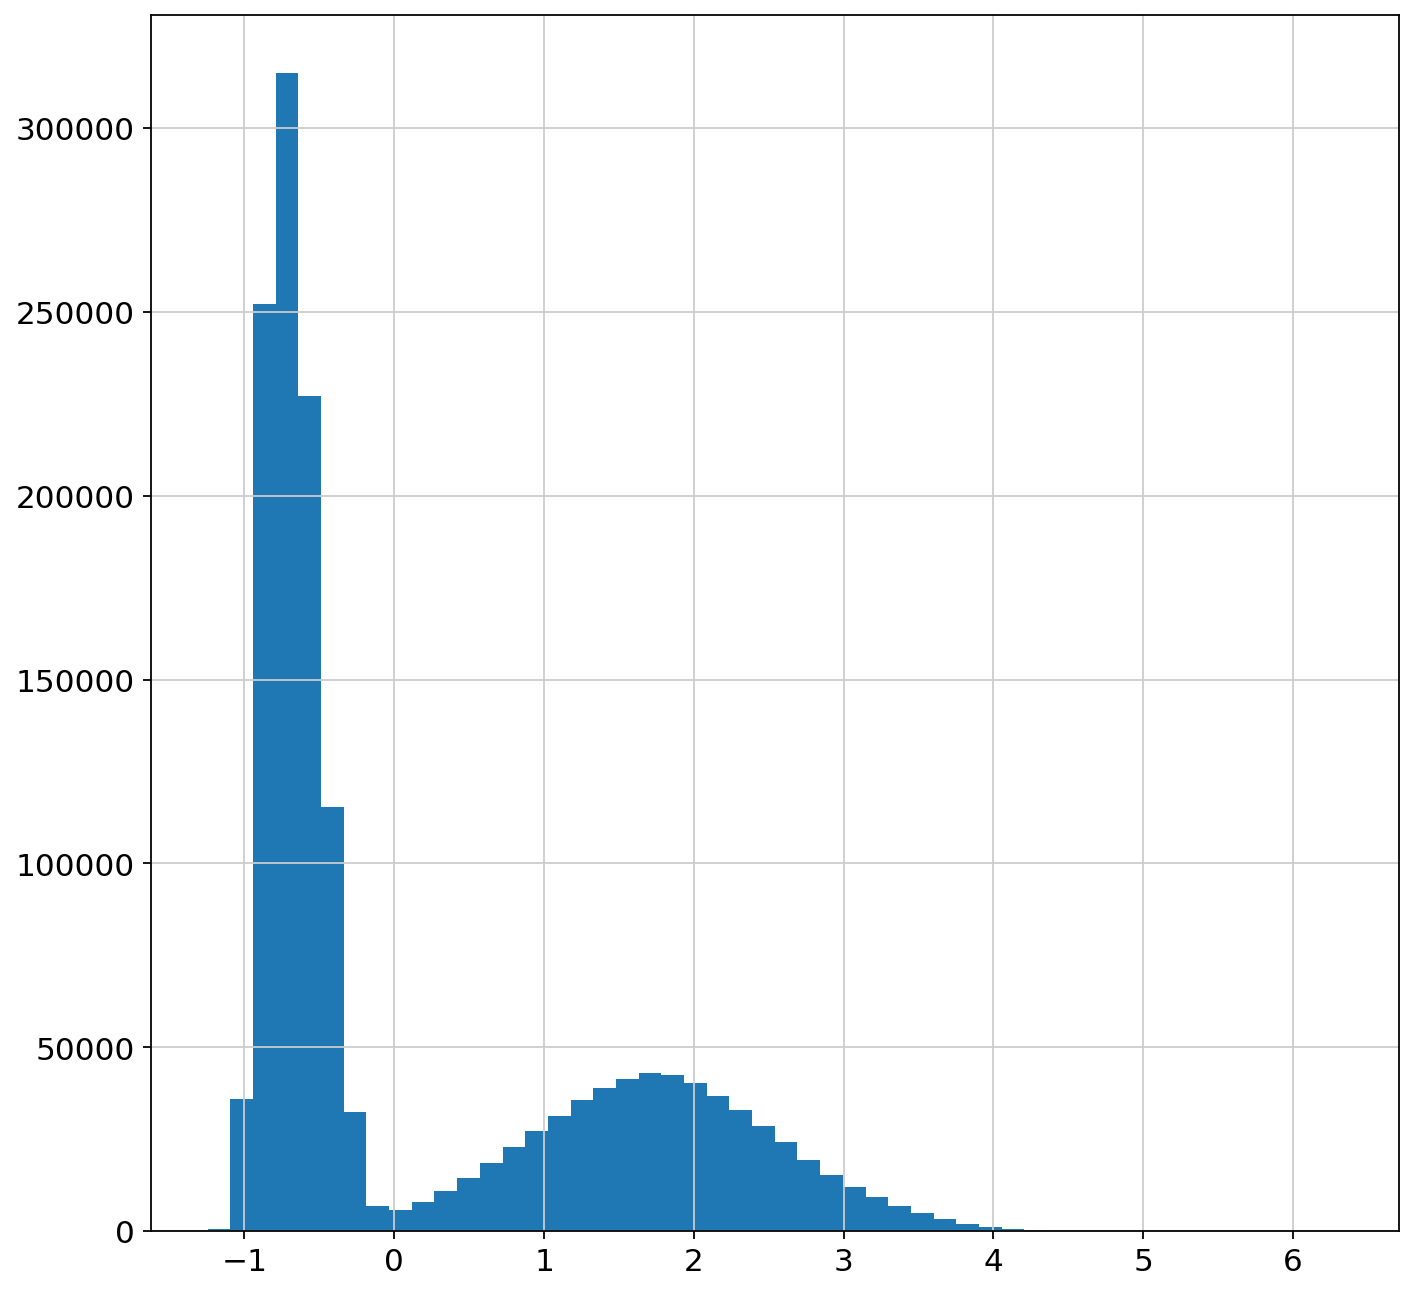

In [8]:
sex_adata.obs['XistScore'].hist(bins=50)

<Axes: >

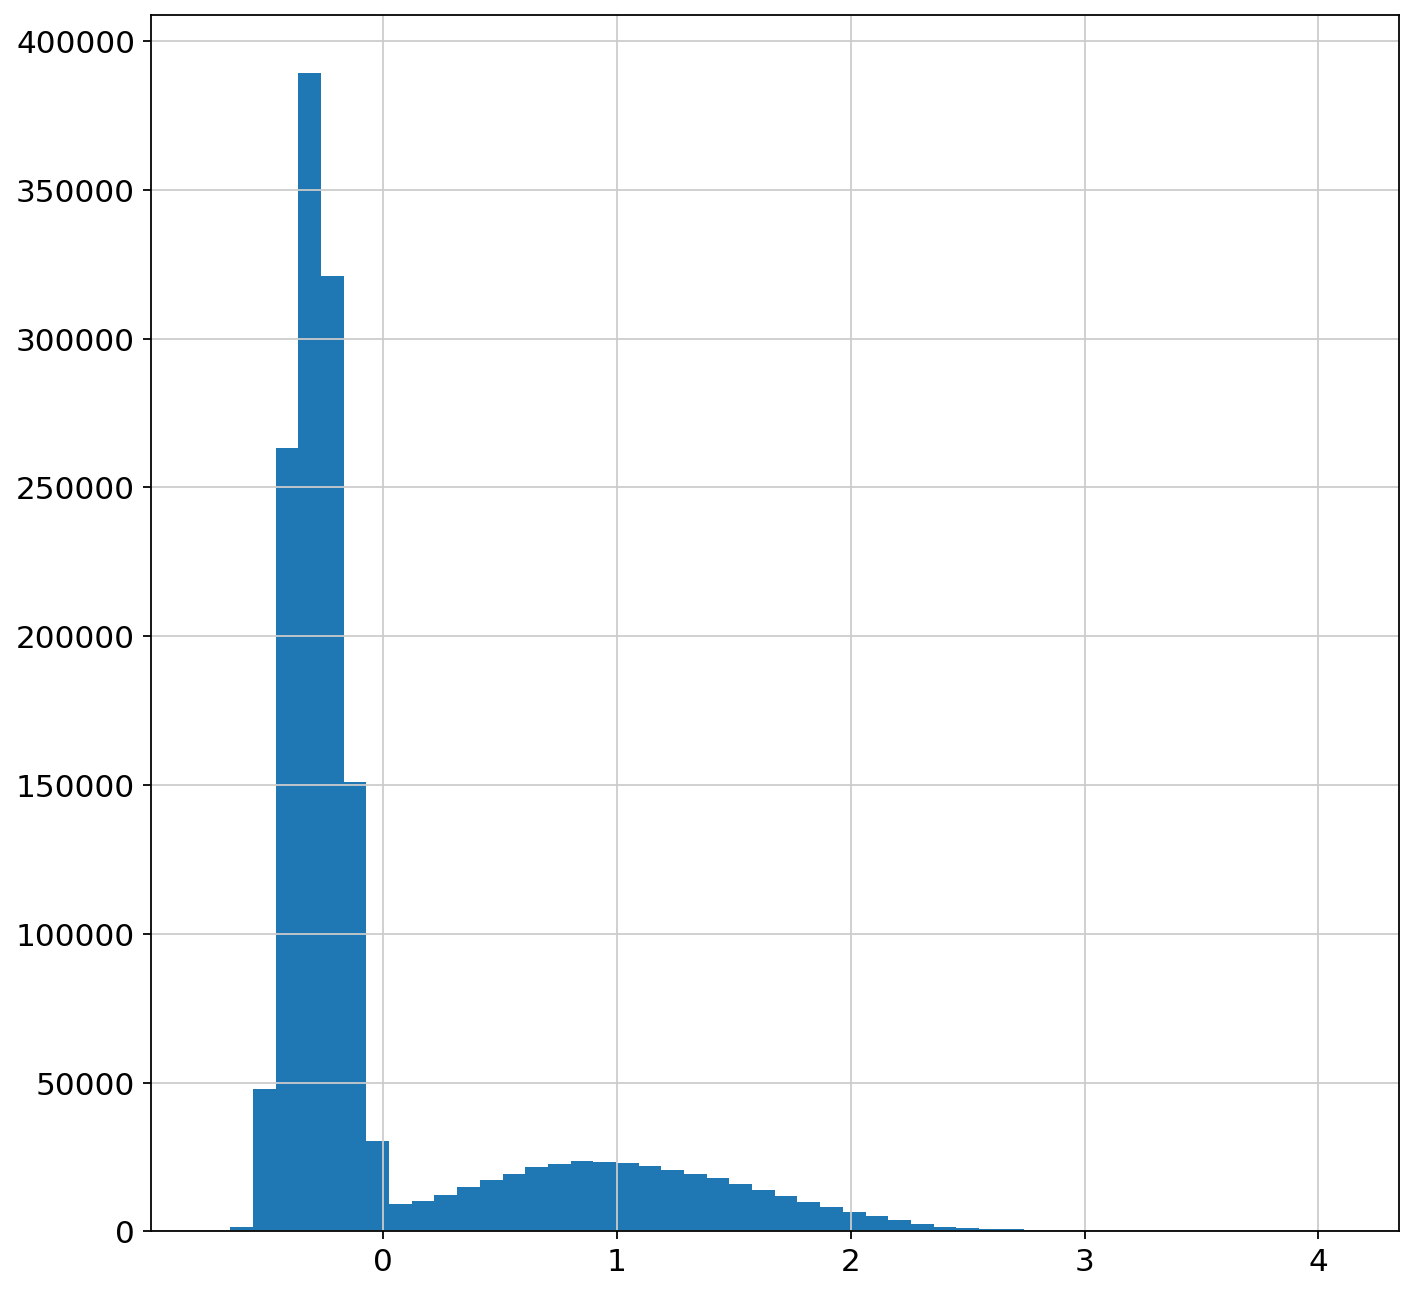

In [9]:
sex_adata.obs['UtyScore'].hist(bins=50)

In [ ]:
adata.obs["XistExpressing"] = sex_adata.obs.XistScore > 0
adata.obs["UtyExpressing"] = sex_adata.obs.UtyScore > 0

### calculate the percentage of cells of a sample expressing Xist and Uty

In [11]:
sex_distrib = adata.obs.loc[:, ["XistExpressing", "UtyExpressing", "Sample"]].groupby("Sample").mean().reset_index()

In [12]:
sex_distrib["author_sex"] = sex_distrib.Sample.map(adata.obs.loc[:, ["Sample", "Author_Sex_harmonized"]].drop_duplicates().set_index("Sample").to_dict()["Author_Sex_harmonized"])

In [13]:
sex_distrib.author_sex = sex_distrib.author_sex.astype(str)

### glance at the distribution

 given the data, 0.1 and 0.01 seem like sensible thresholds to infer sex

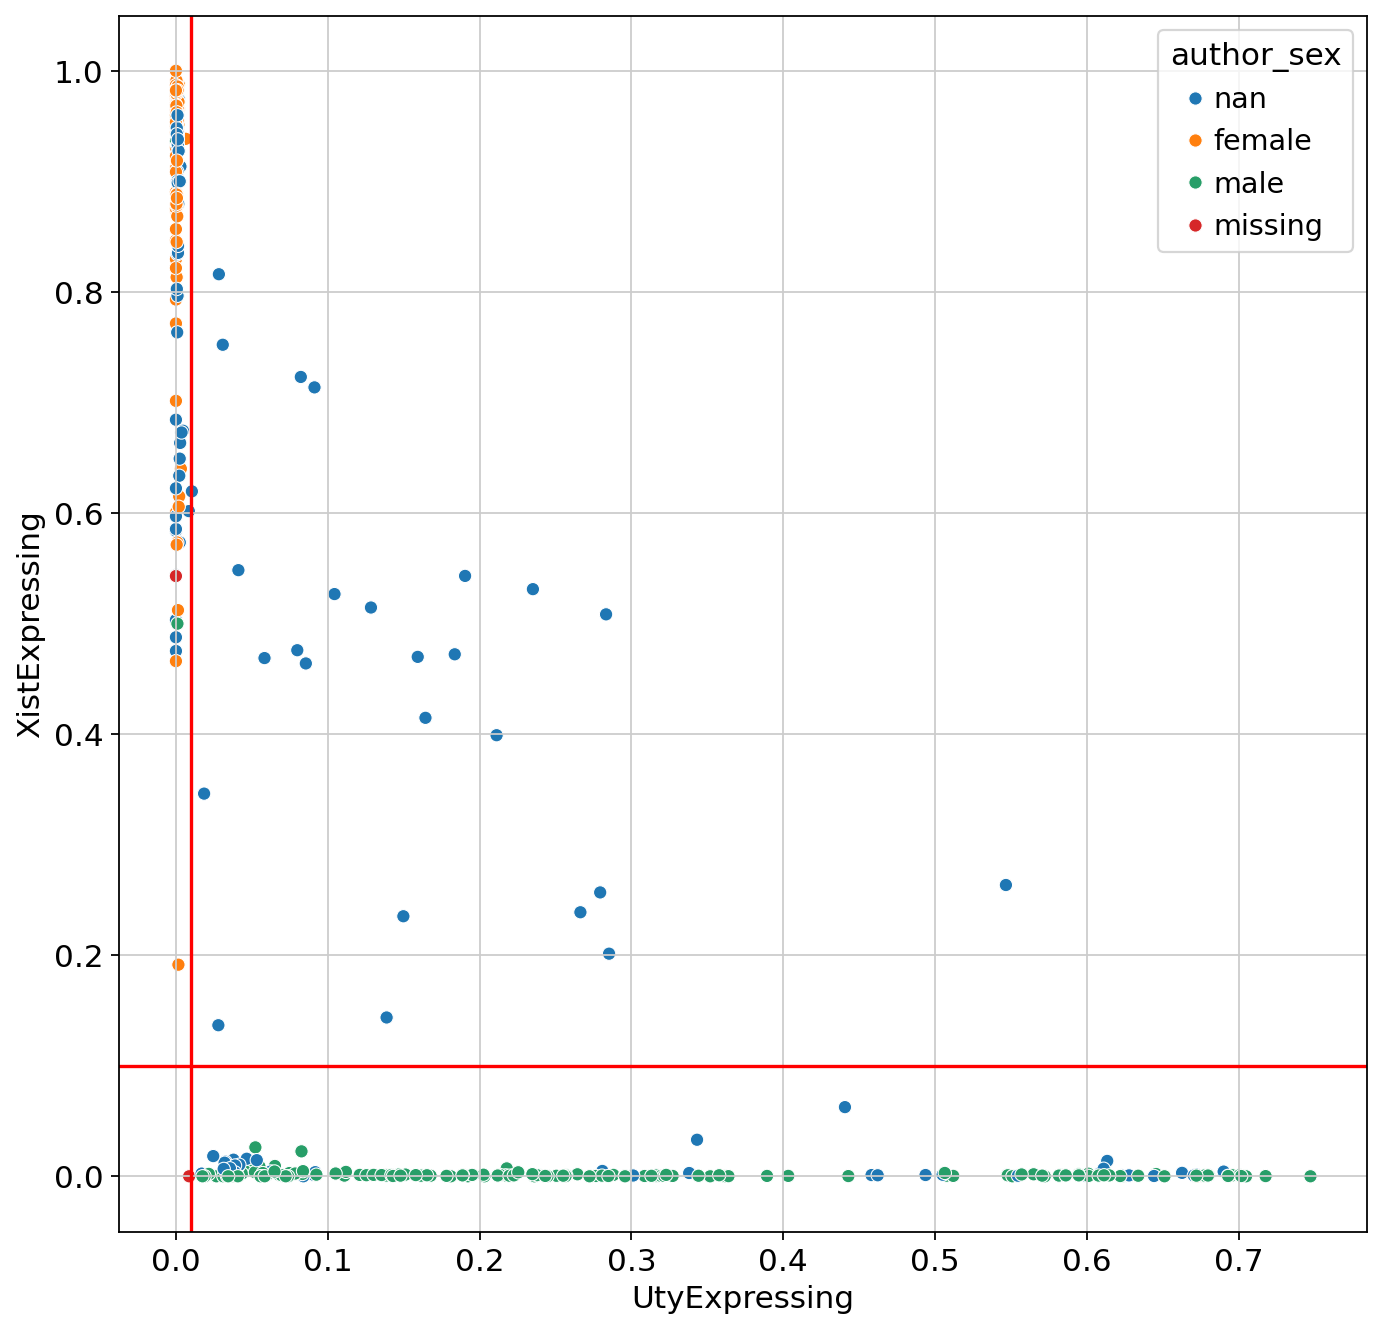

In [14]:
sns.scatterplot(sex_distrib, x="UtyExpressing", y="XistExpressing", hue="author_sex")

plt.axhline(0.1, color='red')
plt.axvline(0.01, color='red')

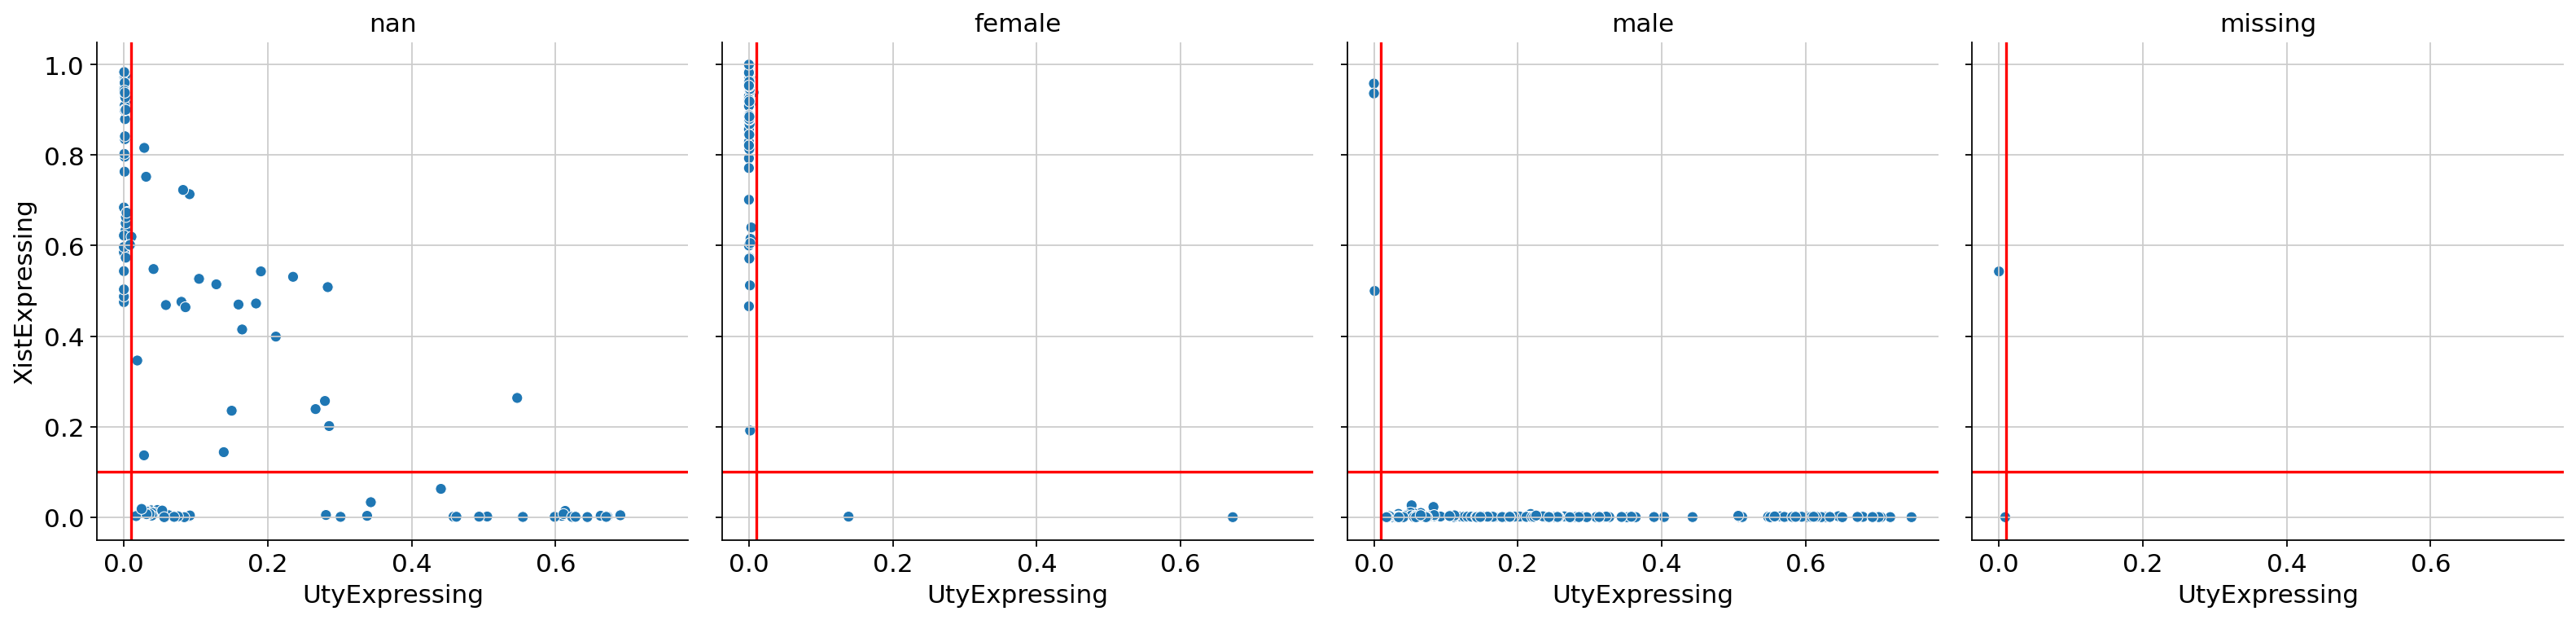

In [15]:

# Set up the FacetGrid: one subplot per unique 'author_sex'
g = sns.FacetGrid(sex_distrib, col="author_sex", height=5, aspect=1)

# Map the scatterplot to each subplot
g.map_dataframe(
    sns.scatterplot, x="UtyExpressing", y="XistExpressing", hue="author_sex", legend=False
)

# Add threshold lines to each plot
for ax in g.axes.flat:
    ax.axhline(0.1, color='red')
    ax.axvline(0.01, color='red')

# Optional: Adjust plot layout
g.set_titles(col_template="{col_name}")
g.set_axis_labels("UtyExpressing", "XistExpressing")
g.tight_layout()

plt.show()


### infer sex

In [ ]:
uty_thr = 0.01
xist_thr = 0.1

sex_distrib["sex_inferred"] = "mixed"
sex_distrib.loc[(sex_distrib.UtyExpressing > uty_thr) & (sex_distrib.XistExpressing <= xist_thr), "sex_inferred"] = "male"
sex_distrib.loc[(sex_distrib.UtyExpressing <= uty_thr) & (sex_distrib.XistExpressing > xist_thr), "sex_inferred"] = "female"

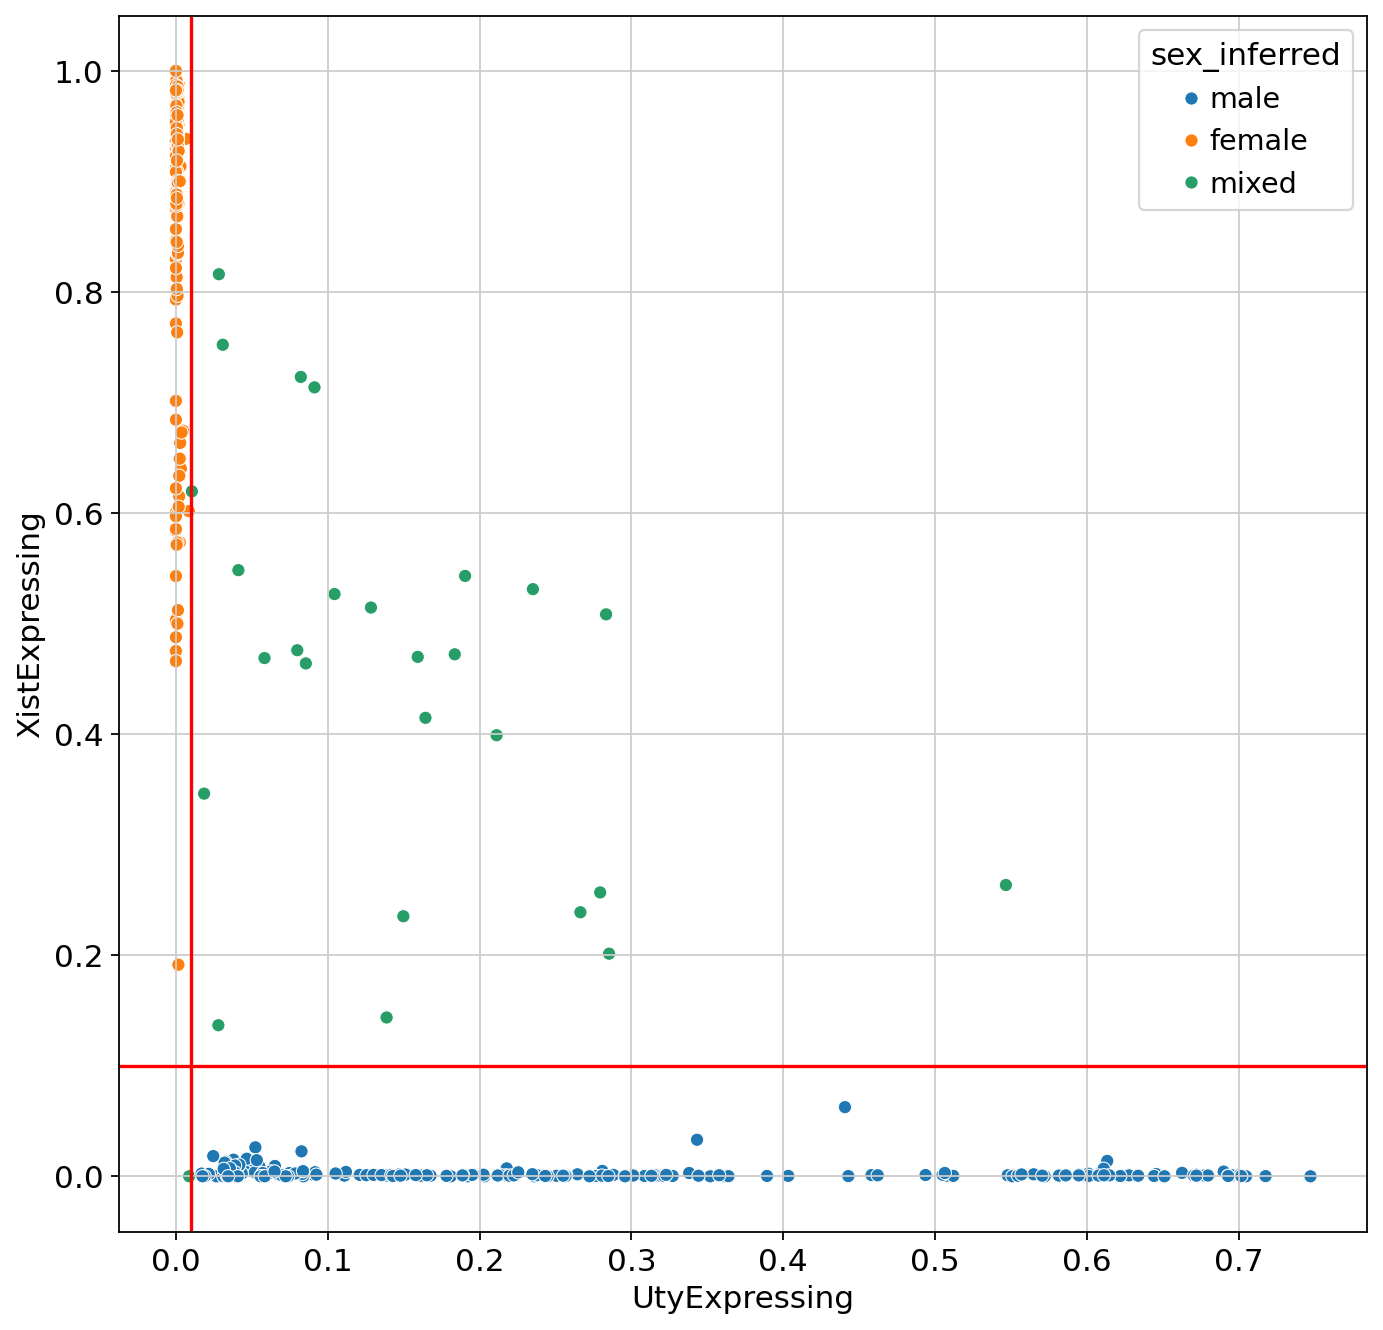

In [17]:
sns.scatterplot(sex_distrib, x="UtyExpressing", y="XistExpressing", hue="sex_inferred")

plt.axhline(0.1, color='red')
plt.axvline(0.01, color='red')

### looking at the samples that have changed sex:

the sample that has 0,0 is from the Zeisel Mousebrain.org dataset. it is the only dataset which also has our "missing" annotation besides also having concrete assignments of sex. they used both sexes, so it may be better to keep it as mixed rather than having it labeled as the opposite sex. 

In [18]:
sex_distrib[sex_distrib.Sample.str.contains("SC1-13")].sort_values(by=["XistExpressing", "UtyExpressing"]).head()

,Sample,XistExpressing,UtyExpressing,author_sex,sex_inferred
116,SC1-13_SAMN08730999,0.000000,0.008696,missing,mixed
107,SC1-13_SAMN08730884,0.000000,0.019208,male,male
114,SC1-13_SAMN08730986,0.000000,0.026762,male,male
115,SC1-13_SAMN08730987,0.000482,0.027952,male,male
109,SC1-13_SAMN08730919,0.466019,0.000000,female,female


for datasets SC2-22 and SC1-10, there are samples that appear to have been switched by the authors.

apart from that, the sample from SC1-06 must be female if 95% of the cells express Xist!

In [19]:
sex_distrib[(sex_distrib.sex_inferred == "male") & (sex_distrib.author_sex == "female")].sort_values(by=["XistExpressing", "UtyExpressing"])

,Sample,XistExpressing,UtyExpressing,author_sex,sex_inferred
340,SC2-22_SAMN44516436,0.000000,0.672611,female,male
94,SC1-10_SAMN10741813,0.001154,0.138462,female,male


In [20]:
sex_distrib[(sex_distrib.sex_inferred == "female") & (sex_distrib.author_sex == "male")].sort_values(by=["XistExpressing", "UtyExpressing"])

,Sample,XistExpressing,UtyExpressing,author_sex,sex_inferred
341,SC2-22_SAMN44516437,0.499901,0.000986,male,female
95,SC1-10_SAMN10741814,0.936293,0.000000,male,female
62,SC1-06_SAMN14341538,0.958187,0.000000,male,female


### map sex into .obs

In [ ]:
sex_mapper = sex_distrib[["Sample", "sex_inferred"]].set_index("Sample").to_dict()["sex_inferred"]
xist_mapper = sex_distrib[["Sample", "XistExpressing"]].set_index("Sample").to_dict()["XistExpressing"]
uty_mapper = sex_distrib[["Sample", "UtyExpressing"]].set_index("Sample").to_dict()["UtyExpressing"]

In [22]:
adata.obs["sex_per_sample_inferred"] = adata.obs.Sample.map(sex_mapper)
adata.obs["xist_pct_per_sample"] = adata.obs.Sample.map(xist_mapper)
adata.obs["uty_pct_per_sample"] = adata.obs.Sample.map(uty_mapper)

### DEV: add old labels for preliminary annotation

In [ ]:
v6 = sc.read_h5ad("/REDACTED-path/datasets/HypoMap3D_compiled/v0.6/singlecell/sc_anndata_all.h5ad",backed="r")


In [24]:
def rearrange_cellid(s: str) -> str:
    """ helper function to translate from old to new cellID naming convention"""
    left, right = s.split("_", 1)
    return f"{right}_{left}"

v6.obs_names = pd.Series(v6.obs_names).apply(lambda x : rearrange_cellid(x))
intersecting_cells = list(set(v6.obs_names).intersection(set(adata.obs_names)))
v6_labels = v6.obs.loc[intersecting_cells, [c for c in v6.obs.columns if "descr" in c]]
v6_labels.columns = [c + "_v0.6" for c in v6_labels.columns]

In [25]:
def build_mapper(df, level):
    col = level
    descr_col = f"{level}_descr_v0.6"

    # Step 1: compute proportions
    counts = (
        df.groupby([col, descr_col])
          .size()
          .rename("count")
          .reset_index()
    )

    totals = counts.groupby(col)["count"].transform("sum")
    counts["prop"] = counts["count"] / totals

    # Step 2: pick most likely descriptor per label
    best = (
        counts.sort_values(["prop"], ascending=False)
              .drop_duplicates(subset=[col])
              .set_index(col)[descr_col]
              .to_dict()
    )

    # Step 3: deduplicate descriptor values
    seen = {}
    deduped = {}

    for k, v in best.items():
        if v not in seen:
            seen[v] = 0
            deduped[k] = v
        else:
            seen[v] += 1
            deduped[k] = f"{v}-{seen[v]}"

    # Step 4: strip everything before first space
    def strip_prefix(s):
        if " " in s:
            return s.split(" ", 1)[1]
        return s

    final_map = {k: strip_prefix(v) for k, v in deduped.items()}

    return final_map

In [26]:
adata.obs = adata.obs.join(v6_labels, how="left")

In [27]:
mappers = {}

for level in ["L2", "L3", "L4", "L5"]:
    mappers[level] = build_mapper(adata.obs.loc[adata.obs.IsControl,:], level)

In [28]:
for level in ["L2", "L3", "L4", "L5"]:
    adata.obs[f"{level}_prelim"] = adata.obs[level].astype(str) + " " + adata.obs[level].astype(str).map(mappers[level])

In [29]:
adata.obs.head()

,CellID,Dataset,Sample,total_counts,n_genes,pct_mito,Author,Source,Data_source_link,GEO,...,uty_pct_per_sample,L1_descr_v0.6,L2_descr_v0.6,L3_descr_v0.6,L4_descr_v0.6,L5_descr_v0.6,L2_prelim,L3_prelim,L4_prelim,L5_prelim
SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01_SAMN18754353_AAACCCACAACCAGAG,SC1-01,SC1-01_SAMN18754353,17459.0,5884,0.131737,Affinati,SRA,NaN,GSE172204,...,0.608683,Gl1-6 HY Glut,Gl2-73 VMH Nr5a1.Sox5,Gl3-204 VMH Nkx2-2,Gl4-756 VMH Nkx2-2.Ros1,Gl5-1059 VMH Nkx2-2.Ros1,Gl2-35 VMH Nr5a1.Sox5,Gl3-113 VMH Nkx2-2,Gl4-290 VMH Nkx2-2.Ros1,Gl5-390 VMH Nkx2-2.Ros1
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01_SAMN18754353_AAACCCAGTCATCTAG,SC1-01,SC1-01_SAMN18754353,17067.0,5727,0.117185,Affinati,SRA,NaN,GSE172204,...,0.608683,Gl1-6 HY Glut,Gl2-71 VMH Fezf1,Gl3-195 VMH Npffr1,Gl4-725 VMH Npffr1.Qrfpr,Gl5-1016 VMH Npffr1.Qrfpr,Gl2-33 VMH Fezf1,Gl3-107 VMH Npffr1,Gl4-274 VMH Npffr1.Qrfpr,Gl5-371 VMH Npffr1.Qrfpr-1
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,SC1-01,SC1-01_SAMN18754353,11905.0,4965,0.201596,Affinati,SRA,NaN,GSE172204,...,0.608683,Gl1-6 HY Glut,Gl2-73 VMH Nr5a1.Sox5,Gl3-206 VMH Megf11,Gl4-767 VMH Megf11.Satb2,Gl5-1072 VMH Megf11.Satb2.Barx2,Gl2-35 VMH Nr5a1.Sox5,Gl3-111 VMH Megf11,Gl4-286 VMH Megf11.Satb2,Gl5-386 VMH Megf11.Scn7a
SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,SC1-01,SC1-01_SAMN18754353,12268.0,5205,0.171177,Affinati,SRA,NaN,GSE172204,...,0.608683,Gl1-6 HY Glut,Gl2-73 VMH Nr5a1.Sox5,Gl3-204 VMH Nkx2-2,Gl4-757 VMH Nkx2-2.Ror1,Gl5-1060 VMH Nkx2-2.Ror1,Gl2-35 VMH Nr5a1.Sox5,Gl3-113 VMH Nkx2-2,Gl4-291 VMH Nkx2-2.Pantr1,Gl5-391 VMH Nkx2-2.Pantr1
SC1-01_SAMN18754353_AAACGAATCGCATAGT,SC1-01_SAMN18754353_AAACGAATCGCATAGT,SC1-01,SC1-01_SAMN18754353,17021.0,5854,0.158628,Affinati,SRA,NaN,GSE172204,...,0.608683,Gl1-6 HY Glut,Gl2-73 VMH Nr5a1.Sox5,Gl3-205 VMH Adamts9,Gl4-762 VMH Adamts9.Pde3a,Gl5-1066 VMH Adamts9.Pde3a,Gl2-35 VMH Nr5a1.Sox5,Gl3-114 VMH Adamts9,Gl4-297 VMH Adamts9.Tll2,Gl5-398 VMH Adamts9.Tll2-1


### save

In [30]:
with tracker.register(ADATA_OUT_FP) as tf:
    tf.set_description('Full sc Hypomap3D (C + NC) with sex inferred per sample.')
    write_clean_h5ad(adata, tf.filepath)

... storing 'Author_Sex_harmonized' as categorical
... storing 'sex_per_sample_inferred' as categorical
... storing 'L2_prelim' as categorical
... storing 'L3_prelim' as categorical
... storing 'L4_prelim' as categorical
... storing 'L5_prelim' as categorical
